# EDA de las tres fuentes

Análisis exploratorio previo a las transformaciones del pipeline. Se revisan estructura,
tipos, nulos, duplicados y valores atípicos de cada fuente, y al final se resumen las decisiones que
se derivan de cada hallazgo.

| Fuente | Origen | Acceso |
|---|---|---|
| Lecturas históricas de clima y aire | World Weather Repository (Kaggle) | archivo CSV |
| Emisiones y economía por país | Our World in Data | base de datos PostgreSQL (`source.owid_co2`), consulta SQL |
| Aire y clima diarios recientes | Open-Meteo | API pública |

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from sqlalchemy import text

from utils.config_loader import ROOT
from utils.db_connector import get_engine

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
IMG = ROOT / "docs" / "img"


## 1. Fuente CSV: lecturas de clima y calidad del aire

In [2]:
csv = pd.read_csv(ROOT / "data/raw/GlobalWeatherRepository.csv.gz")
fecha = pd.to_datetime(csv["last_updated"]).dt.normalize()
print(f"filas: {len(csv):,} | columnas: {csv.shape[1]} | rango: {fecha.min().date()} -> {fecha.max().date()}")
csv.dtypes.value_counts()

filas: 164,109 | columnas: 41 | rango: 2024-05-16 -> 2026-09-08


float64    23
str        11
int64       7
Name: count, dtype: int64

In [3]:
csv.head(3).T.head(20)

,0,1,2
country,Afghanistan,Albania,Algeria
location_name,Kabul,Tirana,Algiers
latitude,34.52,41.33,36.76
longitude,69.18,19.82,3.05
timezone,Asia/Kabul,Europe/Tirane,Africa/Algiers
last_updated_epoch,1715849100,1715849100,1715849100
last_updated,2024-05-16 13:15,2024-05-16 10:45,2024-05-16 09:45
temperature_celsius,26.6,19.0,23.0
temperature_fahrenheit,79.8,66.2,73.4
condition_text,Partly Cloudy,Partly cloudy,Sunny


### Nulos

In [4]:
nulos = csv.isna().mean().sort_values(ascending=False)
con_nulos = nulos[nulos > 0]
print(con_nulos.round(4).to_string() if len(con_nulos) else "ninguna columna tiene nulos")
print("columnas sin nulos:", int((nulos == 0).sum()), "de", csv.shape[1])

ninguna columna tiene nulos
columnas sin nulos: 41 de 41


### Duplicados

In [5]:
dup_exactos = csv.duplicated().sum()
por_dia = csv.groupby(["country", "location_name", fecha]).size()
print("filas duplicadas exactas:", dup_exactos)
print("pares ciudad-día con más de una lectura:", int((por_dia > 1).sum()), "| máximo de lecturas en un día:", int(por_dia.max()))

filas duplicadas exactas: 0
pares ciudad-día con más de una lectura: 383 | máximo de lecturas en un día: 2


### Ciudades y países: nombres y coordenadas

In [6]:
ciudades = csv.groupby(["country", "location_name"]).agg(
    lecturas=("last_updated", "size"), coordenadas=("latitude", lambda s: s.round(4).nunique()),
    dif_lat=("latitude", lambda s: s.max() - s.min()))
print("combinaciones país-ciudad:", len(ciudades), "| países distintos:", csv["country"].nunique())
print("ciudades con más de una coordenada:", int((ciudades["coordenadas"] > 1).sum()),
      "| mayor diferencia de latitud dentro de una ciudad:", round(ciudades["dif_lat"].max(), 2), "grados")
fuera_ingles = [p for p in csv["country"].unique() if not p.isascii() or p in ("Inde", "Jemen", "Komoren", "Letonia", "Estonie", "Mexique")]
print("ejemplos de países con nombre en otro idioma:", fuera_ingles[:12])

combinaciones país-ciudad: 286 | países distintos: 211
ciudades con más de una coordenada: 166 | mayor diferencia de latitud dentro de una ciudad: 0.15 grados
ejemplos de países con nombre en otro idioma: ['Malásia', 'Komoren', 'كولومبيا', 'Estonie', 'Гватемала', 'Inde', 'Letonia', 'Польша', 'Mexique', 'Polônia', 'Турция', 'Südkorea']


### Distribuciones y valores atípicos

In [7]:
num = ["temperature_celsius", "humidity", "wind_kph", "pressure_mb", "air_quality_PM2.5", "air_quality_PM10", "air_quality_Ozone"]
csv[num].describe(percentiles=[.5, .99]).round(2).T

,count,mean,std,min,50%,99%,max
temperature_celsius,164109.0,21.46,9.35,-29.80,23.70,39.20,79.30
humidity,164109.0,67.00,23.50,2.00,72.00,100.00,100.00
wind_kph,164109.0,12.73,11.10,3.60,10.80,37.10,2963.20
pressure_mb,164109.0,1013.98,10.00,771.00,1014.00,1031.00,3006.00
air_quality_PM2.5,164109.0,22.80,34.68,0.10,13.15,152.44,1614.10
air_quality_PM10,164109.0,45.74,141.30,-1848.15,18.70,456.58,6037.29
air_quality_Ozone,164109.0,57.86,31.03,0.00,54.00,157.00,480.70


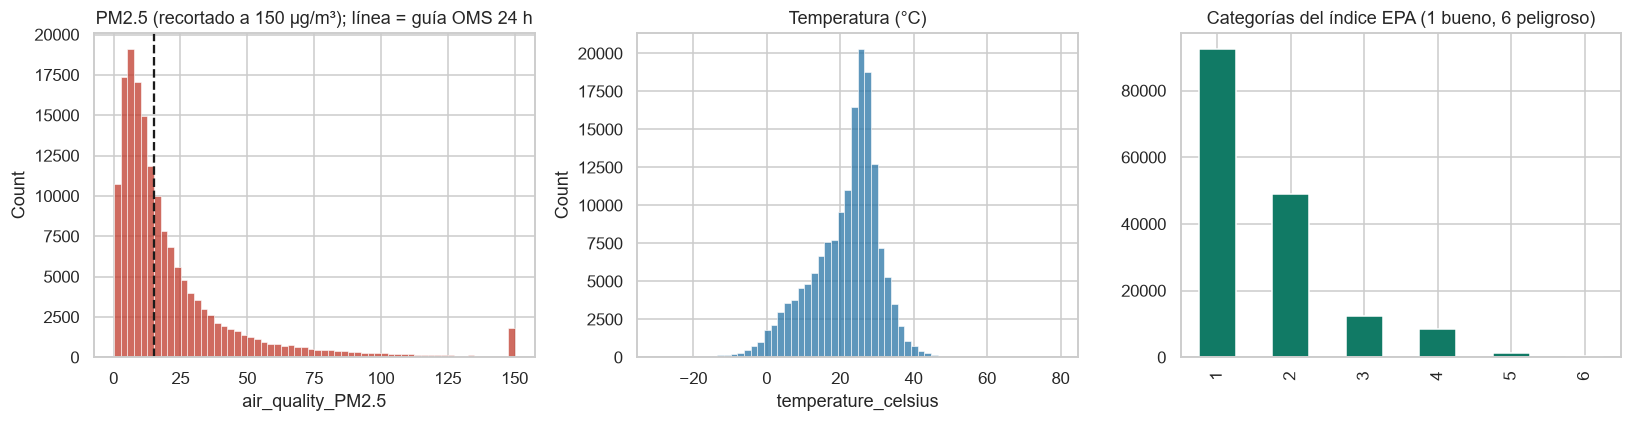

In [8]:
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(csv["air_quality_PM2.5"].clip(upper=150), bins=60, ax=ejes[0], color="#c0392b")
ejes[0].axvline(15, ls="--", color="k"); ejes[0].set_title("PM2.5 (recortado a 150 µg/m³); línea = guía OMS 24 h")
sns.histplot(csv["temperature_celsius"], bins=60, ax=ejes[1], color="#2874a6"); ejes[1].set_title("Temperatura (°C)")
csv["air_quality_us-epa-index"].value_counts().sort_index().plot.bar(ax=ejes[2], color="#117a65")
ejes[2].set_title("Categorías del índice EPA (1 bueno, 6 peligroso)"); ejes[2].set_xlabel("")
fig.tight_layout(); fig.savefig(IMG / "eda_distribuciones_csv.png"); plt.show()

In [9]:
def iqr_atipicos(s):
    q1, q3 = s.quantile([.25, .75])
    lim = q3 + 1.5 * (q3 - q1)
    return int((s > lim).sum()), round(lim, 1)


for col in ["air_quality_PM2.5", "air_quality_PM10", "wind_kph", "precip_mm"]:
    n, lim = iqr_atipicos(csv[col].dropna())
    print(f"{col}: {n:,} valores por encima del límite IQR ({lim})")
csv.assign(fecha=fecha).nlargest(5, "air_quality_PM10")[["location_name", "country", "fecha", "air_quality_PM10", "air_quality_PM2.5"]]

air_quality_PM2.5: 13,816 valores por encima del límite IQR (54.8)
air_quality_PM10: 17,468 valores por encima del límite IQR (83.2)
wind_kph: 3,142 valores por encima del límite IQR (34.1)
precip_mm: 32,621 valores por encima del límite IQR (0.1)


,location_name,country,fecha,air_quality_PM10,air_quality_PM2.5
51796,Riyadh,Saudi Arabia,2025-02-07,6037.29,553.150
51601,Riyadh,Saudi Arabia,2025-02-06,5899.28,611.610
41305,Riyadh,Saudi Arabia,2024-12-15,5858.02,530.580
68948,Riyadh,Saudi Arabia,2025-05-06,5623.63,621.970
37990,Riyadh,Saudi Arabia,2024-11-28,5554.81,563.325


In [10]:
cols_no_neg = ["air_quality_PM2.5", "air_quality_PM10", "air_quality_Carbon_Monoxide", "precip_mm", "wind_kph", "pressure_mb"]
negativos = (csv[cols_no_neg] < 0).sum()
print("valores negativos por columna:")
print(negativos[negativos > 0].to_string())
print("humedad fuera de 0-100:", int((~csv["humidity"].between(0, 100)).sum()))

valores negativos por columna:
air_quality_PM10               2
air_quality_Carbon_Monoxide    1
humedad fuera de 0-100: 0


### Categorías principales

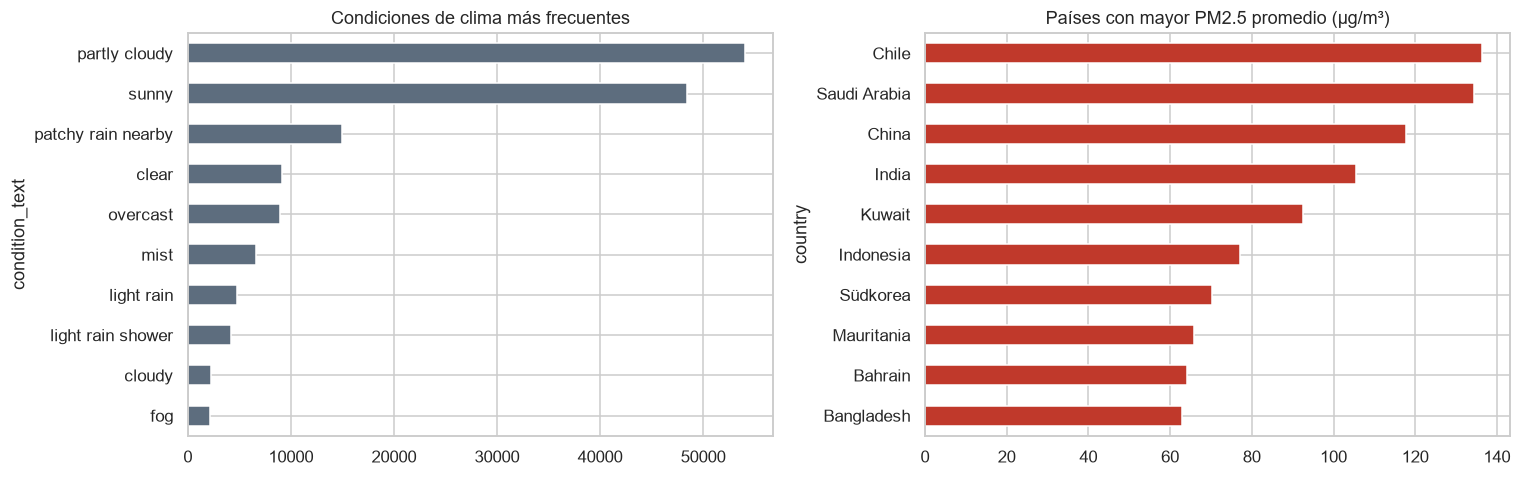

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
csv["condition_text"].str.strip().str.lower().value_counts().head(10).sort_values().plot.barh(ax=ejes[0], color="#5d6d7e")
ejes[0].set_title("Condiciones de clima más frecuentes")
csv.groupby("country")["air_quality_PM2.5"].mean().nlargest(10).sort_values().plot.barh(ax=ejes[1], color="#c0392b")
ejes[1].set_title("Países con mayor PM2.5 promedio (µg/m³)")
fig.tight_layout(); plt.show()

## 2. Fuente base de datos: emisiones por país (OWID)

In [12]:
engine = get_engine()
with engine.connect() as conn:
    owid = pd.read_sql(text("select * from source.owid_co2"), conn)
print(f"filas: {len(owid):,} | columnas: {owid.shape[1]} | años: {owid['year'].min()} -> {owid['year'].max()}")
print("filas sin código ISO (agregados como World, Africa, etc.):", int(owid["iso_code"].isna().sum()))
owid[["country", "iso_code", "year", "population", "gdp", "co2", "co2_per_capita"]].dtypes

filas: 50,411 | columnas: 79 | años: 1750 -> 2024
filas sin código ISO (agregados como World, Africa, etc.): 7931


country               str
iso_code              str
year                int64
population        float64
gdp               float64
co2               float64
co2_per_capita    float64
dtype: object

In [13]:
ultimo = owid[owid["year"] == owid["year"].max()]
clave = ["population", "gdp", "co2", "co2_per_capita", "total_ghg", "energy_per_capita"]
print("porcentaje de nulos en el último año por indicador:")
print((ultimo[clave].isna().mean() * 100).round(1).to_string())
print()
print("último año con dato de PIB:", int(owid.dropna(subset=["gdp"])["year"].max()))

porcentaje de nulos en el último año por indicador:
population             9.8
gdp                  100.0
co2                    2.8
co2_per_capita         9.1
total_ghg             14.2
energy_per_capita     14.6

último año con dato de PIB: 2022


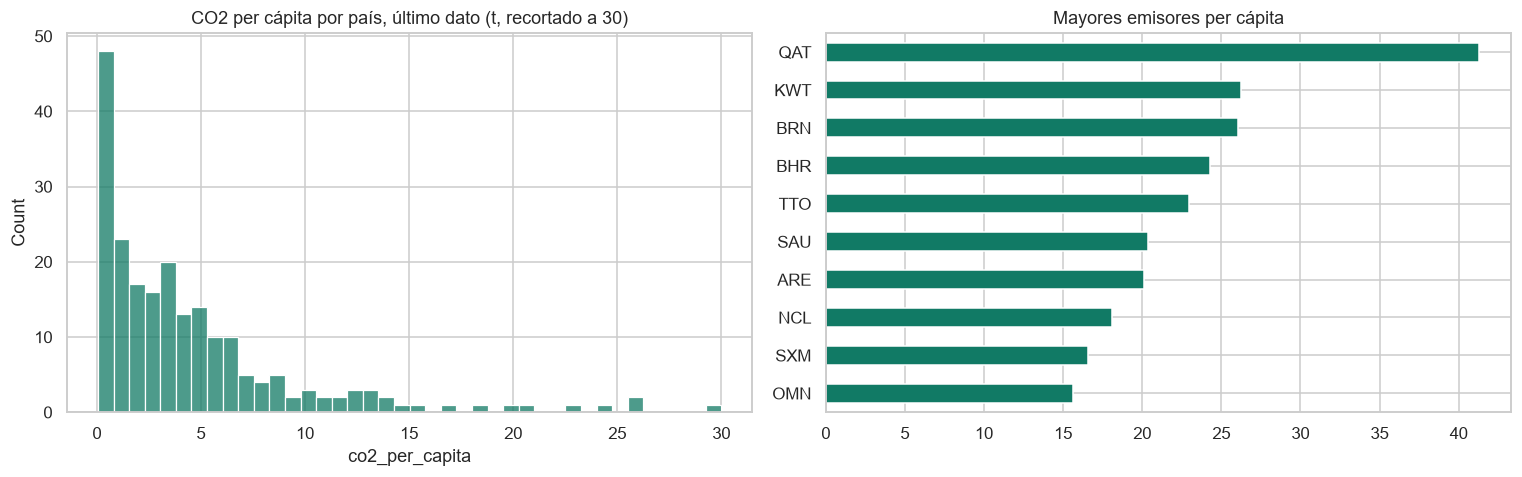

In [14]:
paises = owid.dropna(subset=["iso_code"])
paises = paises[~paises["iso_code"].str.startswith("OWID_")]
ult = paises.dropna(subset=["co2_per_capita"]).sort_values("year").groupby("iso_code").last()
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(ult["co2_per_capita"].clip(upper=30), bins=40, ax=ejes[0], color="#117a65")
ejes[0].set_title("CO2 per cápita por país, último dato (t, recortado a 30)")
ult.nlargest(10, "co2_per_capita")["co2_per_capita"].sort_values().plot.barh(ax=ejes[1], color="#117a65")
ejes[1].set_title("Mayores emisores per cápita"); ejes[1].set_ylabel("")
fig.tight_layout(); fig.savefig(IMG / "eda_distribuciones_owid.png"); plt.show()

## 3. Fuente API: Open-Meteo

In [15]:
ciudades_prueba = {"Bogota": (4.61, -74.08), "Delhi": (28.64, 77.22), "Santiago": (-33.45, -70.67)}
p = {"latitude": ",".join(str(v[0]) for v in ciudades_prueba.values()),
     "longitude": ",".join(str(v[1]) for v in ciudades_prueba.values()),
     "hourly": "pm2_5,pm10,us_aqi", "past_days": 7, "forecast_days": 1, "timezone": "auto"}
resp = requests.get("https://air-quality-api.open-meteo.com/v1/air-quality", params=p, timeout=30).json()
horas = pd.concat([pd.DataFrame(r["hourly"]).assign(ciudad=n) for r, n in zip(resp, ciudades_prueba)], ignore_index=True)
print("respuesta: lista con", len(resp), "ubicaciones | unidades:", resp[0]["hourly_units"])
print("horas por ciudad:", horas.groupby("ciudad").size().to_dict(), "| nulos:", horas[["pm2_5", "pm10", "us_aqi"]].isna().sum().to_dict())
horas["dia"] = pd.to_datetime(horas["time"]).dt.date
print("horas por día (la última fecha es parcial):")
horas.groupby(["ciudad", "dia"]).size().unstack(0).tail(3)

respuesta: lista con 3 ubicaciones | unidades: {'time': 'iso8601', 'pm2_5': 'μg/m³', 'pm10': 'μg/m³', 'us_aqi': 'USAQI'}
horas por ciudad: {'Bogota': 192, 'Delhi': 192, 'Santiago': 192} | nulos: {'pm2_5': 0, 'pm10': 0, 'us_aqi': 0}
horas por día (la última fecha es parcial):


ciudad,Bogota,Delhi,Santiago
dia,,,
2026-09-27,24,24,24
2026-09-28,24,24,24
2026-09-29,24,24,24


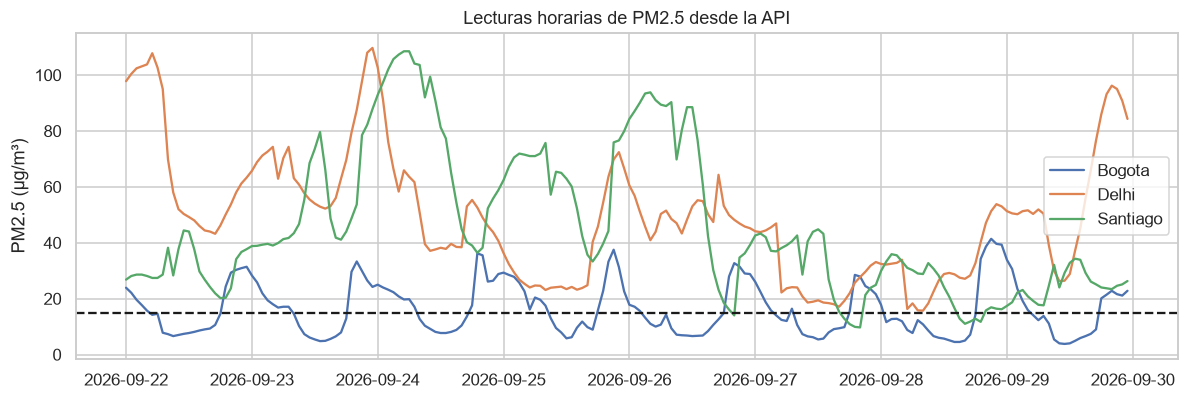

In [16]:
fig, ax = plt.subplots(figsize=(11, 3.8))
for nombre, g in horas.groupby("ciudad"):
    ax.plot(pd.to_datetime(g["time"]), g["pm2_5"], label=nombre)
ax.axhline(15, ls="--", color="k")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Lecturas horarias de PM2.5 desde la API")
ax.legend()
fig.tight_layout(); plt.show()

## 4. Compatibilidad entre fuentes

In [17]:
mapa = pd.read_csv(ROOT / "config/paises_iso3.csv")
iso_csv = set(mapa["iso3"])
iso_owid = set(paises["iso_code"])
print("países del CSV (nombres únicos):", len(mapa), "| ISO3 distintos tras normalizar:", len(iso_csv))
print("ISO3 del CSV sin datos en OWID:", sorted(iso_csv - iso_owid))
print("países de OWID sin ciudades en el CSV:", len(iso_owid - iso_csv))

países del CSV (nombres únicos): 211 | ISO3 distintos tras normalizar: 191
ISO3 del CSV sin datos en OWID: ['XKX']
países de OWID sin ciudades en el CSV: 28


## 5. Hallazgos y decisiones de transformación

| Hallazgo | Decisión |
|---|---|
| 383 pares ciudad-día tienen dos lecturas | conservar la más reciente por ciudad y día |
| 33 nombres de país en otros idiomas o variantes (por ejemplo `Südkorea`, `Польша`, `火鸡`) | tabla de referencia `config/paises_iso3.csv` que normaliza a ISO3 y nombre estándar |
| Las coordenadas de una misma ciudad cambian con el tiempo y algunas ciudades aparecen con dos nombres | ubicación canónica por país y ciudad, con las coordenadas de la lectura más reciente |
| Valores negativos en contaminantes (pocas filas) | descartar esas filas |
| Una lectura de 79.3 °C en Suva (Fiyi), físicamente imposible | descartar temperaturas fuera de -90 a 60 °C |
| PM10 llega a más de 6,000 µg/m³ en Riad | son tormentas de polvo reales; el límite de validación es 10,000 y no 2,000 |
| El PIB no tiene datos recientes y 7,931 filas de OWID son agregados sin ISO | tomar el último dato disponible por indicador y país y excluir agregados |
| La API entrega horas, el CSV una lectura por día | agregar la API a promedio diario, exigir 18 horas o más y excluir el día en curso |
| La API y el CSV se solapan en fechas | la API solo aporta días posteriores al último día del CSV |
| El índice EPA del CSV es categórico (1 a 6), la API entrega el AQI numérico | derivar la categoría EPA del AQI |
